# Week 1 Lab: Teach a line to learn
## Linear regression from first principles to PyTorch

**Expected runtime:** 90 minutes  
**Submission:** completed notebook with all checks passing and short written interpretations  
**Maximum score:** 4 points

In this lab you will train your first machine-learning model. One noisy regression problem will be solved three ways:

1. NumPy with gradients derived by hand;
2. PyTorch with automatic differentiation;
3. PyTorch with `Dataset`, `DataLoader`, and mini-batches.

The model stays the same. What changes is how we calculate gradients and feed data to the training loop.

## The five parts of an ML task

By the end of the lab, you should be able to identify:

- **data:** input values and target values;
- **model:** a rule that converts an input into a prediction;
- **loss:** a number measuring prediction error;
- **optimization:** repeated parameter updates that reduce training loss;
- **evaluation:** evidence from data that did not update the parameters.

Complete the eight `TODO(student)` tasks in order. Do not change the seed, split, or assertions merely to make a check pass.

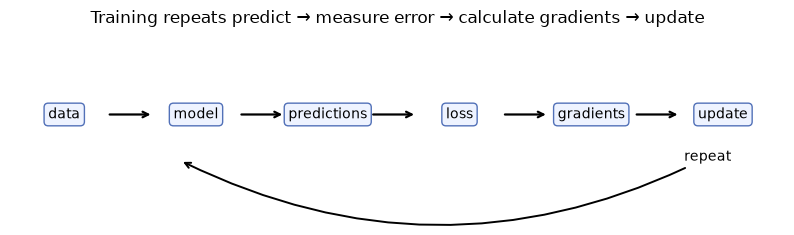

In [2]:
# @title Diagram: the learning loop
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 2.4))
ax.axis("off")
labels = ["data", "model", "predictions", "loss", "gradients", "update"]
positions = [0.07, 0.24, 0.41, 0.58, 0.75, 0.92]
for x, label in zip(positions, labels):
    ax.text(x, .55, label, ha="center", va="center",
            bbox=dict(boxstyle="round", fc="#EEF3FF", ec="#5271B8"))
for left, right in zip(positions[:-1], positions[1:]):
    ax.annotate("", (right - .055, .55), (left + .055, .55),
                arrowprops=dict(arrowstyle="->", lw=1.6))
ax.annotate("repeat", (.22, .30), (.90, .30), ha="center",
            arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-.25", lw=1.4))
ax.set_title("Training repeats predict → measure error → calculate gradients → update")
plt.show()

## Meet the data · 10 minutes

We generate a small synthetic dataset from

$$
y = 1.75x - 0.40 + \varepsilon,
\qquad
\varepsilon \sim \mathcal{N}(0,0.45^2).
$$

Here $x$ is the **input**, $y$ is the **target**, and $\varepsilon$ is random noise. Because of noise, the observations do not lie perfectly on one line.

We separate validation observations before fitting anything. Every implementation will use exactly the same training and validation data.

In [3]:
import random

import numpy as np
import torch
from IPython.display import Markdown, display
from torch import nn
from torch.utils.data import DataLoader, Dataset

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

TRUE_W, TRUE_B = 1.75, -0.40

ModuleNotFoundError: No module named 'torch'

In [ ]:
rng = np.random.default_rng(SEED)
x_all = np.linspace(-3.0, 3.0, 160, dtype=np.float64).reshape(-1, 1)
noise = rng.normal(0.0, 0.45, size=x_all.shape)
y_all = TRUE_W * x_all + TRUE_B + noise

permutation = rng.permutation(len(x_all))
split = int(0.8 * len(x_all))
train_ids, val_ids = permutation[:split], permutation[split:]
x_train_np, y_train_np = x_all[train_ids], y_all[train_ids]
x_val_np, y_val_np = x_all[val_ids], y_all[val_ids]

assert len(x_train_np) == 128 and len(x_val_np) == 32
assert set(train_ids).isdisjoint(val_ids)
assert x_train_np.shape == y_train_np.shape == (128, 1)
print("training:", x_train_np.shape, "| validation:", x_val_np.shape)

In [ ]:
x_line = np.linspace(-3.0, 3.0, 200)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.scatter(x_train_np, y_train_np, alpha=.6, label="training")
ax.scatter(x_val_np, y_val_np, marker="x", s=55, label="validation")
ax.plot(x_line, TRUE_W * x_line + TRUE_B, "k--", label="data-generating line")
ax.set(xlabel="input x", ylabel="target y", title="One problem, one fixed split")
ax.legend(frameon=False)
plt.show()

Our model is another line:

$$
\hat y = wx+b.
$$

The prediction is $\hat y$. The **parameters** $w$ and $b$ are the numbers training will change. We begin with $w=0$ and $b=0$, which gives a horizontal line and poor predictions.

In [ ]:
initial_predictions = np.zeros_like(y_train_np)
example_ids = np.arange(10)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.scatter(x_train_np, y_train_np, color="#5271B8", alpha=.45, label="training data")
ax.plot(x_line, np.zeros_like(x_line), color="#E45756", label="initial model")
ax.vlines(x_train_np[example_ids, 0], 0, y_train_np[example_ids, 0],
          color="#F2C14E", alpha=.9, label="example residuals")
ax.set(xlabel="x", ylabel="y", title="A residual is the vertical prediction error")
ax.legend(frameon=False)
plt.show()

## Loss and three kinds of gradient · 20 minutes

A residual is prediction minus target:

$$
r_i=\hat y_i-y_i.
$$

Mean squared error averages the squared residuals:

$$
L=\operatorname{MSE}(y,\hat y)
=\frac{1}{N}\sum_{i=1}^{N}(\hat y_i-y_i)^2.
$$

A smaller MSE means that predictions are closer to targets on average. Squaring prevents positive and negative residuals from cancelling.

### Task 1/8 — Implement mean squared error

In [ ]:
def mse_loss(y_true, y_pred):
    # TODO(student): return mean((y_pred - y_true) ** 2)
    raise NotImplementedError("Complete Task 1")

In [ ]:
simple_targets = np.array([0.0, 2.0])
simple_predictions = np.array([0.0, 4.0])
assert np.isclose(mse_loss(simple_targets, simple_predictions), 2.0)
print("Task 1 passed: the simple MSE is 2.0")

### Numerical differentiation

A gradient tells us how loss changes when a parameter changes. Without deriving a formula, we can move a parameter slightly in both directions and observe the loss:

$$
\frac{\partial L}{\partial w}
\approx
\frac{L(w+h,b)-L(w-h,b)}{2h}.
$$

This **central finite difference** is an approximation. It needs loss evaluations near the current parameter value.

In [ ]:
check_w, check_b, check_h = 0.30, -0.20, 1e-5
visual_h = 0.08  # exaggerated only so the two plotted points are visible
w_values = np.linspace(check_w - .30, check_w + .30, 120)
losses_near_w = [mse_loss(y_train_np, w * x_train_np + check_b) for w in w_values]

fig, ax = plt.subplots(figsize=(6.8, 3.8))
ax.plot(w_values, losses_near_w)
ax.scatter([check_w - visual_h, check_w + visual_h],
           [mse_loss(y_train_np, (check_w - visual_h) * x_train_np + check_b),
            mse_loss(y_train_np, (check_w + visual_h) * x_train_np + check_b)],
           color="#E45756", zorder=3)
ax.axvline(check_w, color="gray", ls="--", lw=1)
ax.set(xlabel="w", ylabel="MSE", title="Two nearby loss values estimate the slope at the dashed line")
plt.show()

### Task 2/8 — Implement numerical gradients

In [ ]:
def numerical_gradients(x, y, w, b, h=1e-5):
    # TODO(student): evaluate the loss at w ± h and b ± h
    # Return central finite-difference estimates for dL/dw and dL/db.
    raise NotImplementedError("Complete Task 2")

In [ ]:
numerical_dw, numerical_db = numerical_gradients(
    x_train_np, y_train_np, check_w, check_b, check_h
)
assert np.isfinite(numerical_dw) and np.isfinite(numerical_db)
print(f"numerical: dL/dw={numerical_dw:.6f}, dL/db={numerical_db:.6f}")

### Analytical differentiation

For this model and MSE, calculus gives exact formulas:

$$
\frac{\partial L}{\partial w}
=\frac{2}{N}\sum_i x_i(\hat y_i-y_i),
$$

$$
\frac{\partial L}{\partial b}
=\frac{2}{N}\sum_i(\hat y_i-y_i).
$$

The error term $\hat y-y$ appears in both derivatives. The slope gradient also contains $x$ because changing the slope affects predictions in proportion to the input.

### Task 3/8 — Implement the analytical gradients

In [ ]:
def analytical_gradients(x, y_true, y_pred):
    # TODO(student): implement the two formulas above
    raise NotImplementedError("Complete Task 3")

In [ ]:
check_predictions = check_w * x_train_np + check_b
analytical_dw, analytical_db = analytical_gradients(
    x_train_np, y_train_np, check_predictions
)
assert np.allclose(
    [numerical_dw, numerical_db], [analytical_dw, analytical_db], atol=1e-5
)
print(f"analytical: dL/dw={analytical_dw:.6f}, dL/db={analytical_db:.6f}")
print("Task 3 passed: numerical and analytical gradients agree.")

### Automatic differentiation

PyTorch **autograd** records tensor operations and applies the chain rule backward through them. It is not finite differences and it does not search nearby parameter values.

We now ask autograd for the gradient at exactly the same parameters used above.

In [ ]:
x_check = torch.tensor(x_train_np, dtype=torch.float64)
y_check = torch.tensor(y_train_np, dtype=torch.float64)
w_check = torch.tensor(check_w, dtype=torch.float64, requires_grad=True)
b_check = torch.tensor(check_b, dtype=torch.float64, requires_grad=True)

autograd_loss = ((w_check * x_check + b_check - y_check) ** 2).mean()
autograd_loss.backward()
autograd_dw = w_check.grad.item()
autograd_db = b_check.grad.item()

assert np.allclose([autograd_dw, autograd_db],
                   [analytical_dw, analytical_db], atol=1e-10)
print(f"autograd:  dL/dw={autograd_dw:.6f}, dL/db={autograd_db:.6f}")

In [ ]:
gradient_rows = [
    ("Numerical", numerical_dw, numerical_db),
    ("Analytical", analytical_dw, analytical_db),
    ("Autograd", autograd_dw, autograd_db),
]
table = "| Method | dL/dw | dL/db | distance from analytical |\n|---|---:|---:|---:|\n"
for name, dw, db in gradient_rows:
    difference = np.linalg.norm([dw - analytical_dw, db - analytical_db])
    table += f"| {name} | {dw:.6f} | {db:.6f} | {difference:.2e} |\n"
display(Markdown(table))

positions = np.arange(2)
for offset, (name, dw, db) in zip([-.24, 0, .24], gradient_rows):
    plt.bar(positions + offset, [dw, db], width=.22, label=name)
plt.xticks(positions, ["dL/dw", "dL/db"])
plt.title("Three ways to obtain the same gradient")
plt.legend(frameon=False)
plt.show()

**Checkpoint.** Numerical differentiation is valuable for checking a gradient, but it needs extra loss evaluations for every parameter. Autograd can calculate gradients for millions of parameters in one backward pass.

The next experiment changes the finite-difference step size. For this particular quadratic loss, the central difference is mathematically exact apart from floating-point effects. Extremely small steps are actually worse because subtraction and rounding begin to dominate. More general losses can also suffer approximation error when the step is too large.

In [ ]:
step_sizes = np.logspace(-1, -10, 10)
approximation_errors = []
for h in step_sizes:
    dw, db = numerical_gradients(x_train_np, y_train_np, check_w, check_b, h)
    approximation_errors.append(np.linalg.norm([dw - analytical_dw, db - analytical_db]))

plt.loglog(step_sizes, approximation_errors, marker="o")
plt.gca().invert_xaxis()
plt.xlabel("finite-difference step h")
plt.ylabel("distance from analytical gradient")
plt.title("For quadratic MSE, extremely small h exposes rounding error")
plt.show()

## Solution 1 — NumPy gradient descent · 15 minutes

Gradient descent moves each parameter opposite to its gradient:

$$
w \leftarrow w-\eta
rac{\partial L}{\partial w},
\qquad
b \leftarrow b-\eta
rac{\partial L}{\partial b}.
$$

The learning rate $\eta$ controls the step size. Training will print progress every 25 epochs rather than flooding the notebook with 150 lines.

### Task 4/8 — Complete the NumPy parameter update

In [ ]:
w_np, b_np = 0.0, 0.0
learning_rate = 0.05
numpy_losses = []
numpy_snapshots = {-1: (w_np, b_np)}

for epoch in range(150):
    predictions = w_np * x_train_np + b_np
    loss = mse_loss(y_train_np, predictions)
    dw, db = analytical_gradients(x_train_np, y_train_np, predictions)

    # TODO(student): update w_np and b_np using the learning rate
    raise NotImplementedError("Complete Task 4")

    numpy_losses.append(loss)
    if epoch in {0, 5, 25, 149}:
        numpy_snapshots[epoch] = (w_np, b_np)
    if epoch % 25 == 0 or epoch == 149:
        print(f"epoch {epoch:3d} | train MSE {loss:.4f} | w {w_np:.3f} | b {b_np:.3f}")

In [ ]:
numpy_train_predictions = w_np * x_train_np + b_np
numpy_val_predictions = w_np * x_val_np + b_np
numpy_train_mse = mse_loss(y_train_np, numpy_train_predictions)
numpy_val_mse = mse_loss(y_val_np, numpy_val_predictions)

assert numpy_losses[-1] < 0.1 * numpy_losses[0]
assert abs(w_np - TRUE_W) < 0.15 and abs(b_np - TRUE_B) < 0.15
print(f"final NumPy parameters: w={w_np:.3f}, b={b_np:.3f}")
print(f"validation MSE: {numpy_val_mse:.4f}")

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(x_train_np, y_train_np, alpha=.35)
for epoch, (w, b) in numpy_snapshots.items():
    label = "initial" if epoch == -1 else f"epoch {epoch}"
    ax1.plot(x_line, w * x_line + b, label=label)
ax1.set(title="The line moves toward the data", xlabel="x", ylabel="y")
ax1.legend(frameon=False)

ax2.plot(numpy_losses)
ax2.set(title="NumPy training progress", xlabel="epoch", ylabel="training MSE")
ax2.set_yscale("log")
plt.tight_layout()
plt.show()

The line changes rapidly at first and then stabilizes. The loss curve is evidence that the updates improved predictions on the training data. Validation MSE asks whether the fitted line also predicts held-out observations reasonably well.

## Solution 2 — The same model with PyTorch · 25 minutes

A PyTorch tensor resembles a NumPy array, but it can also participate in automatic differentiation. We convert the same fixed split to `float32` tensors.

In [ ]:
x_train = torch.tensor(x_train_np, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.float32)
x_val = torch.tensor(x_val_np, dtype=torch.float32)
y_val = torch.tensor(y_val_np, dtype=torch.float32)

assert x_train.shape == y_train.shape == (128, 1)
assert x_val.shape == y_val.shape == (32, 1)
print("one sample:", x_train[0], "→ target", y_train[0])

| ML idea | PyTorch object |
|---|---|
| linear model | `nn.Linear(1, 1)` |
| mean squared error | `nn.MSELoss()` |
| update rule | `torch.optim.SGD` |
| calculate gradients | `loss.backward()` |
| reset stored gradients | `optimizer.zero_grad()` |

`nn.Linear(1, 1)` contains exactly the two trainable quantities we already know: one weight and one bias.

### Task 5/8 — Create the model, loss, and optimizer

In [ ]:
torch.manual_seed(SEED)

# TODO(student): create nn.Linear(1, 1), nn.MSELoss(), and SGD(lr=0.05)
model = None
criterion = None
optimizer = None

In [ ]:
assert isinstance(model, nn.Linear)
assert model.in_features == 1 and model.out_features == 1
assert isinstance(criterion, nn.MSELoss)
assert len(list(model.parameters())) == 2
print("Task 5 passed: the model has one weight and one bias.")

One training step must occur in this order:

```text
predictions = model(inputs)
loss = criterion(predictions, targets)
optimizer.zero_grad()
loss.backward()
optimizer.step()
```

PyTorch accumulates gradients by default, so `zero_grad()` prevents gradients from previous steps being added to the current step.

### Task 6/8 — Complete the PyTorch training step

In [ ]:
torch_losses = []

for epoch in range(150):
    predictions = model(x_train)
    loss = criterion(predictions, y_train)

    # TODO(student): zero gradients, backpropagate, and update parameters
    raise NotImplementedError("Complete Task 6")

    torch_losses.append(loss.item())
    if epoch % 25 == 0 or epoch == 149:
        w_now, b_now = model.weight.item(), model.bias.item()
        print(f"epoch {epoch:3d} | train MSE {loss.item():.4f} | w {w_now:.3f} | b {b_now:.3f}")

In [ ]:
model.eval()
with torch.no_grad():
    torch_train_predictions = model(x_train)
    torch_val_predictions = model(x_val)
    torch_train_mse = criterion(torch_train_predictions, y_train).item()
    torch_val_mse = criterion(torch_val_predictions, y_val).item()

torch_w, torch_b = model.weight.item(), model.bias.item()
assert torch_losses[-1] < 0.1 * torch_losses[0]
assert abs(torch_w - w_np) < 0.05 and abs(torch_b - b_np) < 0.05
print(f"final PyTorch parameters: w={torch_w:.3f}, b={torch_b:.3f}")
print(f"validation MSE: {torch_val_mse:.4f}")

In [ ]:
plt.figure(figsize=(7, 3.8))
plt.plot(numpy_losses, label="NumPy: analytical gradients")
plt.plot(torch_losses, "--", label="PyTorch: autograd")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("training MSE")
plt.title("Different gradient machinery, almost the same learning curve")
plt.legend(frameon=False)
plt.show()

> **Milestone:** you have trained your first model with PyTorch.

NumPy used a gradient formula that you wrote. PyTorch created the same kind of gradient from recorded tensor operations. The model, loss, data, learning rate, and update rule remained equivalent.

## Solution 3 — Dataset, DataLoader, and mini-batches · 12 minutes

So far, every update used all 128 training samples. Larger datasets are commonly processed in **mini-batches**.

- A `Dataset` defines how to retrieve one sample.
- A `DataLoader` groups samples into batches and may shuffle training order.
- The model, loss, backpropagation, and optimizer step remain the same.

### Task 7/8 — Implement the Dataset interface

In [ ]:
class RegressionDataset(Dataset):
    def __init__(self, features, targets):
        if len(features) != len(targets):
            raise ValueError("features and targets must have equal length")
        self.features = features
        self.targets = targets

    def __len__(self):
        # TODO(student): return the number of samples
        raise NotImplementedError("Complete Task 7")

    def __getitem__(self, index):
        # TODO(student): return one (feature, target) pair
        raise NotImplementedError("Complete Task 7")

In [ ]:
train_dataset = RegressionDataset(x_train, y_train)
val_dataset = RegressionDataset(x_val, y_val)
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True,
    generator=loader_generator, num_workers=0,
)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)

batch_x, batch_y = next(iter(train_loader))
assert len(train_dataset) == 128 and len(val_dataset) == 32
assert batch_x.shape == batch_y.shape == (16, 1)
print("one batch:", batch_x.shape, "inputs and", batch_y.shape, "targets")

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(x_train, y_train, color="lightgray", label="other training samples")
ax.scatter(batch_x, batch_y, color="#E45756", s=55, label="one mini-batch")
ax.set(xlabel="x", ylabel="y", title="A batch is a small view of the training set")
ax.legend(frameon=False)
plt.show()

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, total_samples = 0.0, 0
    for features, targets in loader:
        predictions = model(features)
        loss = criterion(predictions, targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(features)
        total_samples += len(features)
    return total_loss / total_samples

In [ ]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_samples = 0.0, 0
    with torch.no_grad():
        for features, targets in loader:
            loss = criterion(model(features), targets)
            total_loss += loss.item() * len(features)
            total_samples += len(features)
    return total_loss / total_samples

### Task 8/8 — Train with mini-batches and track validation loss

In [ ]:
torch.manual_seed(SEED)
batch_model = nn.Linear(1, 1)
batch_criterion = nn.MSELoss()
batch_optimizer = torch.optim.SGD(batch_model.parameters(), lr=0.03)
train_history, val_history = [], []

for epoch in range(40):
    # TODO(student): train for one epoch, evaluate, and append both losses
    raise NotImplementedError("Complete Task 8")

    if epoch % 5 == 0 or epoch == 39:
        print(f"epoch {epoch:2d} | train MSE {train_loss:.4f} | validation MSE {val_loss:.4f}")

In [ ]:
assert len(train_history) == len(val_history) == 40
assert train_history[-1] < 0.2 * train_history[0]
assert val_history[-1] < 0.5

batch_model.eval()
with torch.no_grad():
    batch_train_predictions = batch_model(x_train)
    batch_val_predictions = batch_model(x_val)
batch_train_mse = batch_criterion(batch_train_predictions, y_train).item()
batch_val_mse = batch_criterion(batch_val_predictions, y_val).item()
batch_w, batch_b = batch_model.weight.item(), batch_model.bias.item()

print(f"final mini-batch parameters: w={batch_w:.3f}, b={batch_b:.3f}")
print(f"validation MSE: {batch_val_mse:.4f}")
print("All eight implementation tasks passed.")

## Compare the three solutions · 8 minutes

The implementations should agree closely because they use the same linear model and MSE objective. Mini-batch updates follow a noisier path because each update sees only part of the training set.

In [ ]:
results = [
    ("NumPy", "analytical", "full batch", w_np, b_np, numpy_train_mse, numpy_val_mse),
    ("PyTorch", "autograd", "full batch", torch_w, torch_b, torch_train_mse, torch_val_mse),
    ("PyTorch", "autograd", "DataLoader", batch_w, batch_b, batch_train_mse, batch_val_mse),
]

comparison = "| Implementation | Gradients | Data feeding | w | b | Train MSE | Validation MSE |\n"
comparison += "|---|---|---|---:|---:|---:|---:|\n"
for implementation, gradients, feeding, w, b, train_mse, val_mse in results:
    comparison += (
        f"| {implementation} | {gradients} | {feeding} | {w:.3f} | {b:.3f} "
        f"| {train_mse:.4f} | {val_mse:.4f} |\n"
    )
display(Markdown(comparison))

In [ ]:
residuals = y_val_np - batch_val_predictions.numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(x_train_np, y_train_np, alpha=.3)
axes[0].plot(x_line, w_np * x_line + b_np, label="NumPy")
axes[0].plot(x_line, torch_w * x_line + torch_b, "--", label="PyTorch full")
axes[0].plot(x_line, batch_w * x_line + batch_b, ":", lw=3, label="PyTorch batches")
axes[0].set(title="Three fitted lines", xlabel="x", ylabel="y")
axes[0].legend(frameon=False)

axes[1].plot(numpy_losses, label="NumPy full")
axes[1].plot(torch_losses, "--", label="PyTorch full")
axes[1].plot(np.linspace(0, 149, 40), train_history, label="mini-batch train")
axes[1].plot(np.linspace(0, 149, 40), val_history, label="mini-batch validation")
axes[1].set(title="Training progress", xlabel="scaled epoch", ylabel="MSE", yscale="log")
axes[1].legend(frameon=False, fontsize=8)

axes[2].scatter(batch_val_predictions, residuals, alpha=.8)
axes[2].axhline(0, color="black", lw=1)
axes[2].set(title="Validation residuals", xlabel="prediction", ylabel="target − prediction")
plt.tight_layout()
plt.show()

## Final interpretation questions

Answer concisely in your own words and refer to your outputs where possible.

1. In this problem, what are the input, target, prediction, and two trainable parameters?
2. What does MSE measure? What would an MSE of zero mean?
3. Describe one complete PyTorch training step in the correct order. Why is `zero_grad()` needed?
4. Why must validation observations not participate in parameter updates?
5. How are numerical differentiation, analytical gradients, and autograd different? Why is numerical differentiation useful but impractical for a model with millions of parameters?
6. Why did the three implementations learn nearly the same line? What changed between them, and what stayed fixed?
7. What evidence in the loss curves and residual plot supports—or challenges—the conclusion that the model learned an appropriate relationship? What might happen with a much smaller or much larger learning rate?

**Your answers:**

1.
2.
3.
4.
5.
6.
7.

## Four-point assessment rubric

| Points | Evidence |
|---:|---|
| 1 | Correct MSE, numerical and analytical gradients, gradient comparison, and NumPy updates |
| 1 | Correct PyTorch model, optimizer, autograd loop, and parameter comparison |
| 1 | Correct `Dataset`/`DataLoader`, mini-batch training, validation, and assertions |
| 1 | Reproducible top-to-bottom run, comparison table, plots, and written interpretation |

## Submission checklist

- [ ] All eight `TODO(student)` tasks are complete.
- [ ] All assertions pass after restarting and running from the top.
- [ ] Training progress is printed and all requested plots appear.
- [ ] The final comparison table contains three implementations.
- [ ] All seven interpretation questions are answered in your own words.
- [ ] Training and validation data remain separate.

## When you need help

<details>
<summary><strong>Open a help-me-mode prompt for ChatGPT, Claude, or another assistant</strong></summary>

```text
You are my tutor for a Week 1 linear-regression lab. Work in help-me mode.

Do not give me a complete solution, fill every TODO, or write an entire notebook cell for me. First ask which task I am working on, then ask for my current attempt and the exact error or result I do not understand.

Give one small hint at a time. Prefer a guiding question, conceptual explanation, pseudocode, or pointer to the relevant formula or PyTorch operation. If code is necessary, show only the smallest fragment needed to explain the idea. After each hint, ask me to make the next change and report what happened.

Help me reason about data, model, predictions, MSE, numerical and analytical gradients, autograd, parameter updates, tensor shapes, Dataset/DataLoader, train/validation separation, loss curves, residuals, and assertions. Never suggest changing the seed, validation split, or tests merely to make a check pass.

I am responsible for testing, understanding, and explaining my submitted work.
```

Test every suggestion. Never paste passwords, tokens, private links, or personal data into a chat.

</details>